# DreamerV3 Adaptive Convergence Run Toward the 96-100% BO Band

This notebook is a new DreamerV3 schedule built on the earlier target95 elite-replay workflow, but with a stricter evaluation objective: converge the evaluation policy into the 96-100% band of the BO optimum.

The main change is adaptive phase switching. The earlier close-gap run discovered near-optimal actions early, but waited too long to move into low-noise exploitation.

This notebook therefore:

- starts with elite-biased replay immediately
- switches from discovery to exploitation as soon as the run shows target-region evidence
- narrows actor noise and recent replay exposure aggressively once strong episodes appear
- stops early only when evaluation is stably inside the success band

In [1]:
from __future__ import annotations

import copy
import importlib
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

import dreamerv3_haberbosch_helpers as dreamer_helpers

hb = importlib.reload(dreamer_helpers)
hb.set_plot_style()

WORKSPACE_DIR = hb.WORKSPACE_DIR
RUN_LOGDIR = WORKSPACE_DIR / 'runs' / 'dreamerv3_haber_bosch_target96to100_adaptive'
SEED = 7

In [2]:
BO_REFERENCE = {
    'reward': 2712.651793,
    'normalized_action': np.array([
        -0.6127335418989747,
        0.08136597881754437,
        0.6577094487733803,
        1.0,
        1.0,
        1.0,
        -1.0,
    ], dtype=np.float32),
}

SUCCESS_MIN_FRACTION = 0.96
STRETCH_FRACTION = 0.98
OPTIMUM_FRACTION = 1.00

SUCCESS_MIN_REWARD = SUCCESS_MIN_FRACTION * BO_REFERENCE['reward']
STRETCH_REWARD = STRETCH_FRACTION * BO_REFERENCE['reward']
OPTIMUM_REWARD = OPTIMUM_FRACTION * BO_REFERENCE['reward']

DISCOVERY_MAX = 700
EXPLOIT_MAX = 1100
LOCK_IN_MAX = 1450

DISCOVERY_BLOCK = 50
EXPLOIT_BLOCK = 25
LOCK_IN_BLOCK = 25

CONVERGENCE_WINDOW = 50
EVAL_STABILITY_WINDOW = 3
REPLAY_SIZE = 192
RUN_LOCK_IN_PHASE = True

pd.DataFrame([
    {
        'bo_reward': BO_REFERENCE['reward'],
        'success_min_fraction': SUCCESS_MIN_FRACTION,
        'stretch_fraction': STRETCH_FRACTION,
        'success_min_reward': SUCCESS_MIN_REWARD,
        'stretch_reward': STRETCH_REWARD,
        'optimum_reward': OPTIMUM_REWARD,
        'discovery_max': DISCOVERY_MAX,
        'exploit_max': EXPLOIT_MAX,
        'lock_in_max': LOCK_IN_MAX,
        'replay_size': REPLAY_SIZE,
        'run_logdir': str(RUN_LOGDIR),
    }
])

,bo_reward,success_min_fraction,stretch_fraction,success_min_reward,stretch_reward,optimum_reward,discovery_max,exploit_max,lock_in_max,replay_size,run_logdir
0,2712.651793,0.96,0.98,2604.145721,2658.398757,2712.651793,700,1100,1450,192,/Users/campatzis/Documents/Research/runs/dream...


In [3]:
def evaluate_normalized_action(environment, action: np.ndarray) -> dict[str, float]:
    environment.reset()
    _, reward, terminated, truncated, info = environment.step(action)
    row = {
        'reward': float(reward),
        'terminated': bool(terminated),
        'truncated': bool(truncated),
    }
    scaled = np.asarray(info.get('scaled_action', np.zeros_like(action)), dtype=np.float64)
    row.update({f'a{index}': float(action[index - 1]) for index in range(1, 8)})
    row.update({f'a{index}_physical': float(scaled[index - 1]) for index in range(1, 8)})
    for name, value in info.items():
        if name == 'scaled_action':
            continue
        if isinstance(value, (int, float, np.integer, np.floating, bool)):
            row[name] = float(value) if not isinstance(value, bool) else bool(value)
    return row

preflight = hb.build_preflight_frame()
display(preflight)
if not preflight['ok'].all():
    missing = preflight.loc[~preflight['ok'], 'item'].tolist()
    raise RuntimeError(f'Preflight failed for: {missing}')

env = hb.make_haber_bosch_env()
try:
    smoke_test = hb.run_smoke_test(env)
    bo_reference_row = evaluate_normalized_action(env, BO_REFERENCE['normalized_action'])
finally:
    env.close()

display(smoke_test.to_frame(name='value'))
baseline_frame = pd.DataFrame([bo_reference_row])
baseline_frame['bo_fraction'] = baseline_frame['reward'] / BO_REFERENCE['reward']
baseline_frame['success_min_reward'] = SUCCESS_MIN_REWARD
baseline_frame['stretch_reward'] = STRETCH_REWARD
display(
    baseline_frame[[
        'reward',
        'bo_fraction',
        'success_min_reward',
        'stretch_reward',
        'nh3_kg_per_s',
        'power_kw',
        'revenue_per_h',
        'energy_cost_per_h',
    ]]
)

,item,value,ok
0,Workspace,/Users/campatzis/Documents/Research,True
1,Flowsheet,/Users/campatzis/Documents/Research/DWSIM Simu...,True
2,Bridge Script,/Users/campatzis/Documents/Research/.dwsim_sup...,True
3,Rosetta Wrapper,/Users/campatzis/Documents/Research/.venv311-r...,True
4,Rosetta Python,/Users/campatzis/Documents/Research/.venv311-r...,True
5,Mono Root,/Users/campatzis/Documents/Research/.mono-runt...,True
6,DWSIM Automation Dir,/Applications/DWSIM.app/Contents/MonoBundle,True
7,Notebook Kernel Architecture,arm64,True


,value
baseline_observation,"[0.0, 0.0, 0.0, 0.0, 0.0]"
step_observation,"[1.9237689962789544, 2448.9456451678902, 425.0..."
reward,737.350075
terminated,False
truncated,False
info,"{'nh3_kg_per_s': 1.9237689962789544, 'nh3_ton_..."


,reward,bo_fraction,success_min_reward,stretch_reward,nh3_kg_per_s,power_kw,revenue_per_h,energy_cost_per_h
0,2712.651793,1.0,2604.145721,2658.398757,2.4751,2814.232893,4455.180451,1742.528658


## Strategy

The prior close-gap run showed the controlling failure mode clearly: Dreamer could still discover excellent single-step actions, but the evaluation policy failed to stabilize near them.

This notebook changes the schedule in three ways:

- **Adaptive discovery:** discovery is short and exits as soon as the run finds target-region evidence instead of waiting for a late fixed episode threshold.
- **Aggressive exploitation:** once a strong region is found, replay shifts harder toward elites, evaluation becomes more frequent, and actor noise is cut quickly.
- **Lock-in squeeze:** a final low-noise phase removes most remaining recent-replay influence and tries to hold evaluation inside the 96-100% BO band.

The success rule is intentionally two-level:

- the run is **successful** if the last few eval checkpoints average at or above 96% of the BO optimum
- the run is **stretch-successful** if that stable eval average reaches 98% or higher

In [4]:
def fraction_of_bo(value: float | int | np.integer | np.floating | None) -> float:
    if value is None:
        return float('nan')
    numeric = float(value)
    if not np.isfinite(numeric):
        return float('nan')
    return numeric / float(BO_REFERENCE['reward'])

def meets_threshold(value: float | int | np.integer | np.floating | None, threshold: float | None) -> bool:
    if threshold is None or value is None:
        return False
    numeric = float(value)
    return bool(np.isfinite(numeric) and numeric >= float(threshold))

def count_completed_episodes(logdir: Path) -> int:
    train_eps = Path(logdir) / 'train_eps'
    return sum(1 for _ in train_eps.glob('*.npz')) if train_eps.exists() else 0

def load_train_metrics(logdir: Path) -> tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame]:
    metrics = hb.load_metrics_frame(logdir)
    train = metrics.loc[metrics['train_return'].notna()].copy()
    train = train.sort_values('step').reset_index(drop=True)
    evals = metrics.loc[metrics['eval_return'].notna()].copy()
    evals = evals.sort_values('step').reset_index(drop=True)
    return metrics, train, evals

def summarize_train_progress(train_df: pd.DataFrame, success_reward: float, window: int) -> tuple[dict[str, float | int | bool], pd.DataFrame]:
    if train_df.empty:
        empty_summary = {
            'episodes': 0,
            'best_train_reward': float('nan'),
            'best_train_fraction': float('nan'),
            'latest_reward': float('nan'),
            'latest_fraction': float('nan'),
            'rolling_mean': float('nan'),
            'rolling_mean_fraction': float('nan'),
            'rolling_hit_rate': float('nan'),
            'target_hits': 0,
            'converged_success_band': False,
        }
        return empty_summary, train_df.copy()

    summary_frame = train_df.copy()
    summary_frame['success_hit'] = summary_frame['train_return'] >= success_reward
    summary_frame['rolling_mean'] = summary_frame['train_return'].rolling(window, min_periods=1).mean()
    summary_frame['rolling_hit_rate'] = summary_frame['success_hit'].rolling(window, min_periods=1).mean()

    best_row = summary_frame.loc[int(summary_frame['train_return'].idxmax())].copy()
    last_row = summary_frame.iloc[-1].copy()
    summary = {
        'episodes': int(len(summary_frame)),
        'best_train_reward': float(best_row['train_return']),
        'best_train_fraction': fraction_of_bo(best_row['train_return']),
        'latest_reward': float(last_row['train_return']),
        'latest_fraction': fraction_of_bo(last_row['train_return']),
        'rolling_mean': float(last_row['rolling_mean']),
        'rolling_mean_fraction': fraction_of_bo(last_row['rolling_mean']),
        'rolling_hit_rate': float(last_row['rolling_hit_rate']),
        'target_hits': int(summary_frame['success_hit'].sum()),
        'converged_success_band': bool(last_row['rolling_mean'] >= success_reward),
    }
    return summary, summary_frame

def summarize_eval_progress(eval_df: pd.DataFrame, success_reward: float, stretch_reward: float, window: int) -> tuple[dict[str, float | int | bool], pd.DataFrame]:
    if eval_df.empty:
        empty_summary = {
            'eval_points': 0,
            'best_eval_return': float('nan'),
            'best_eval_fraction': float('nan'),
            'best_eval_gap_to_success': float('nan'),
            'latest_eval_return': float('nan'),
            'latest_eval_fraction': float('nan'),
            'mean_last_eval': float('nan'),
            'mean_last_eval_fraction': float('nan'),
            'tail_std': float('nan'),
            'eval_success_hits': 0,
            'eval_stretch_hits': 0,
            'stable_success_band': False,
            'stable_stretch_band': False,
        }
        return empty_summary, eval_df.copy()

    summary_frame = eval_df.copy()
    summary_frame['success_hit'] = summary_frame['eval_return'] >= success_reward
    summary_frame['stretch_hit'] = summary_frame['eval_return'] >= stretch_reward
    summary_frame['tail_mean'] = summary_frame['eval_return'].rolling(window, min_periods=1).mean()
    summary_frame['tail_std'] = summary_frame['eval_return'].rolling(window, min_periods=1).std().fillna(0.0)

    best_row = summary_frame.loc[int(summary_frame['eval_return'].idxmax())].copy()
    last_row = summary_frame.iloc[-1].copy()
    summary = {
        'eval_points': int(len(summary_frame)),
        'best_eval_return': float(best_row['eval_return']),
        'best_eval_fraction': fraction_of_bo(best_row['eval_return']),
        'best_eval_gap_to_success': float(success_reward - best_row['eval_return']),
        'latest_eval_return': float(last_row['eval_return']),
        'latest_eval_fraction': fraction_of_bo(last_row['eval_return']),
        'mean_last_eval': float(last_row['tail_mean']),
        'mean_last_eval_fraction': fraction_of_bo(last_row['tail_mean']),
        'tail_std': float(last_row['tail_std']),
        'eval_success_hits': int(summary_frame['success_hit'].sum()),
        'eval_stretch_hits': int(summary_frame['stretch_hit'].sum()),
        'stable_success_band': bool(last_row['tail_mean'] >= success_reward and best_row['eval_return'] >= success_reward),
        'stable_stretch_band': bool(last_row['tail_mean'] >= stretch_reward and best_row['eval_return'] >= stretch_reward),
    }
    return summary, summary_frame

def summarize_replay_selection(logdir: Path, config: hb.DreamerExperimentConfig, success_reward: float) -> tuple[pd.DataFrame, pd.DataFrame]:
    replay_frame = hb.inspect_replay_inventory(logdir / 'train_eps', config, target_reward=success_reward)
    selected = replay_frame.loc[replay_frame['selected_for_replay']].copy()
    return replay_frame, selected

def build_base_config(logdir: Path) -> hb.DreamerExperimentConfig:
    cfg = hb.DreamerExperimentConfig()
    cfg.seed = SEED
    cfg.logdir = logdir
    cfg.seed_logdir_from = None
    cfg.resume_from_checkpoint = None
    cfg.reset_existing_run = True
    cfg.target_episodes = DISCOVERY_BLOCK
    cfg.prefill_steps = 64
    cfg.replay_size = REPLAY_SIZE
    cfg.replay_policy = 'elite_recent'
    cfg.replay_keep_top_episodes = 128
    cfg.replay_keep_recent_episodes = 64
    cfg.eval_every_steps = DISCOVERY_BLOCK
    cfg.log_every_steps = 25
    cfg.eval_episodes = 5
    cfg.train_ratio = 16.0
    cfg.episode_report_frequency = 10
    cfg.dreamer_overrides = {}
    return cfg

def build_phase_config(base_config: hb.DreamerExperimentConfig, phase_spec: dict[str, object], *, reset_existing_run: bool) -> hb.DreamerExperimentConfig:
    cfg = copy.deepcopy(base_config)
    cfg.target_episodes = int(phase_spec['max_episodes'])
    cfg.reset_existing_run = bool(reset_existing_run)
    cfg.replay_size = int(phase_spec['replay_keep_top']) + int(phase_spec['replay_keep_recent'])
    cfg.replay_policy = 'elite_recent'
    cfg.replay_keep_top_episodes = int(phase_spec['replay_keep_top'])
    cfg.replay_keep_recent_episodes = int(phase_spec['replay_keep_recent'])
    cfg.eval_every_steps = int(phase_spec['eval_every_steps'])
    cfg.log_every_steps = int(phase_spec['log_every_steps'])
    cfg.eval_episodes = int(phase_spec['eval_episodes'])
    cfg.train_ratio = float(phase_spec['train_ratio'])
    cfg.episode_report_frequency = int(phase_spec['episode_report_frequency'])
    cfg.dreamer_overrides = copy.deepcopy(phase_spec['dreamer_overrides'])
    return cfg

def phase_plan_frame(phase_specs: list[dict[str, object]]) -> pd.DataFrame:
    rows = []
    for spec in phase_specs:
        actor_cfg = spec['dreamer_overrides']['actor']
        advance_on = spec.get('advance_on', {})
        trigger_text = ', '.join(f'{name}>={float(value):.3f}' for name, value in advance_on.items())
        rows.append(
            {
                'phase': spec['name'],
                'max_episodes': int(spec['max_episodes']),
                'block_size': int(spec['block_size']),
                'replay_keep_top': int(spec['replay_keep_top']),
                'replay_keep_recent': int(spec['replay_keep_recent']),
                'train_ratio': float(spec['train_ratio']),
                'eval_every_steps': int(spec['eval_every_steps']),
                'eval_episodes': int(spec['eval_episodes']),
                'actor_entropy': float(actor_cfg['entropy']),
                'actor_min_std': float(actor_cfg['min_std']),
                'eval_state_mean': bool(spec['dreamer_overrides']['eval_state_mean']),
                'advance_on': trigger_text,
            }
        )
    return pd.DataFrame(rows)

def should_advance_phase(phase_spec: dict[str, object], row: dict[str, float | int | bool | str]) -> tuple[bool, str]:
    triggers = phase_spec.get('advance_on', {})
    assert isinstance(triggers, dict)
    comparisons = [
        ('best_train_fraction', 'best_train_fraction', 'best train fraction'),
        ('best_eval_fraction', 'best_eval_fraction', 'best eval fraction'),
        ('mean_last_eval_fraction', 'mean_last_eval_fraction', 'last eval mean fraction'),
        ('rolling_mean_fraction', 'rolling_mean_fraction', 'rolling train mean fraction'),
    ]
    for row_key, trigger_key, label in comparisons:
        threshold = triggers.get(trigger_key)
        value = row.get(row_key)
        if meets_threshold(value, float(threshold)) if threshold is not None else False:
            return True, f'{label} {float(value):.3f} reached trigger {float(threshold):.3f}'

    completed_episodes = int(row['completed_episodes'])
    max_episodes = int(phase_spec['max_episodes'])
    if completed_episodes >= max_episodes:
        return True, f'completed {completed_episodes} episodes, which matches the phase budget {max_episodes}'
    return False, ''

def compare_run_to_band(logdir: Path, success_reward: float, stretch_reward: float) -> dict[str, float | int | bool | str]:
    metrics_path = Path(logdir) / 'metrics.jsonl'
    if not metrics_path.exists():
        return {
            'logdir': str(logdir),
            'status': 'missing',
        }
    _, train_df, eval_df = load_train_metrics(logdir)
    train_summary, _ = summarize_train_progress(train_df, success_reward, CONVERGENCE_WINDOW)
    eval_summary, _ = summarize_eval_progress(eval_df, success_reward, stretch_reward, EVAL_STABILITY_WINDOW)
    return {
        'logdir': str(logdir),
        'status': 'ok',
        'episodes': int(train_summary['episodes']),
        'best_train_reward': float(train_summary['best_train_reward']),
        'best_train_fraction': float(train_summary['best_train_fraction']),
        'rolling_mean': float(train_summary['rolling_mean']),
        'rolling_mean_fraction': float(train_summary['rolling_mean_fraction']),
        'best_eval_return': float(eval_summary['best_eval_return']),
        'best_eval_fraction': float(eval_summary['best_eval_fraction']),
        'latest_eval_return': float(eval_summary['latest_eval_return']),
        'latest_eval_fraction': float(eval_summary['latest_eval_fraction']),
        'mean_last_eval': float(eval_summary['mean_last_eval']),
        'mean_last_eval_fraction': float(eval_summary['mean_last_eval_fraction']),
        'tail_std': float(eval_summary['tail_std']),
        'stable_success_band': bool(eval_summary['stable_success_band']),
        'stable_stretch_band': bool(eval_summary['stable_stretch_band']),
    }

In [5]:
BASE_CFG = build_base_config(RUN_LOGDIR)

PHASE_SPECS = [
    {
        'name': 'adaptive_discovery',
        'max_episodes': DISCOVERY_MAX,
        'block_size': DISCOVERY_BLOCK,
        'replay_keep_top': 128,
        'replay_keep_recent': 64,
        'train_ratio': 16.0,
        'eval_every_steps': 50,
        'log_every_steps': 25,
        'eval_episodes': 5,
        'episode_report_frequency': 10,
        'advance_on': {
            'best_train_fraction': 0.975,
            'best_eval_fraction': 0.955,
            'rolling_mean_fraction': 0.930,
        },
        'dreamer_overrides': {
            'actor': {
                'entropy': 7.5e-5,
                'min_std': 0.04,
            },
            'eval_state_mean': False,
        },
    },
    {
        'name': 'adaptive_exploit',
        'max_episodes': EXPLOIT_MAX,
        'block_size': EXPLOIT_BLOCK,
        'replay_keep_top': 160,
        'replay_keep_recent': 32,
        'train_ratio': 18.0,
        'eval_every_steps': 25,
        'log_every_steps': 25,
        'eval_episodes': 10,
        'episode_report_frequency': 10,
        'advance_on': {
            'best_eval_fraction': 0.965,
            'mean_last_eval_fraction': 0.955,
            'rolling_mean_fraction': 0.950,
        },
        'dreamer_overrides': {
            'actor': {
                'entropy': 1.0e-5,
                'min_std': 0.015,
            },
            'eval_state_mean': True,
        },
    },
]

if RUN_LOCK_IN_PHASE:
    PHASE_SPECS.append(
        {
            'name': 'lock_in_squeeze',
            'max_episodes': LOCK_IN_MAX,
            'block_size': LOCK_IN_BLOCK,
            'replay_keep_top': 176,
            'replay_keep_recent': 16,
            'train_ratio': 20.0,
            'eval_every_steps': 25,
            'log_every_steps': 25,
            'eval_episodes': 10,
            'episode_report_frequency': 10,
            'advance_on': {
                'mean_last_eval_fraction': 0.970,
                'best_eval_fraction': 0.980,
            },
            'dreamer_overrides': {
                'actor': {
                    'entropy': 0.0,
                    'min_std': 0.008,
                },
                'eval_state_mean': True,
            },
        }
    )

display(phase_plan_frame(PHASE_SPECS))
objective_text = (
    f'**Objective:** complete one DreamerV3 training session that converges the evaluation policy into the **96-100%** BO band, with **{SUCCESS_MIN_REWARD:.3f}** as the success floor and **{STRETCH_REWARD:.3f}** as the stretch target.'
)
display(Markdown(objective_text))

,phase,max_episodes,block_size,replay_keep_top,replay_keep_recent,train_ratio,eval_every_steps,eval_episodes,actor_entropy,actor_min_std,eval_state_mean,advance_on
0,adaptive_discovery,700,50,128,64,16.0,50,5,0.000075,0.040,False,"best_train_fraction>=0.975, best_eval_fraction..."
1,adaptive_exploit,1100,25,160,32,18.0,25,10,0.000010,0.015,True,"best_eval_fraction>=0.965, mean_last_eval_frac..."
2,lock_in_squeeze,1450,25,176,16,20.0,25,10,0.000000,0.008,True,"mean_last_eval_fraction>=0.970, best_eval_frac..."


**Objective:** complete one DreamerV3 training session that converges the evaluation policy into the **96-100%** BO band, with **2604.146** as the success floor and **2658.399** as the stretch target.

In [6]:
RUN_QUICK_VALIDATION = False

if RUN_QUICK_VALIDATION:
    quick_cfg = hb.build_quick_validation_config(
        build_phase_config(BASE_CFG, PHASE_SPECS[0], reset_existing_run=True)
    )
    hb.run_dreamer_training(quick_cfg, run_training=True)
    quick_metrics, quick_train, quick_eval = load_train_metrics(quick_cfg.logdir)
    quick_train_summary, _ = summarize_train_progress(quick_train, SUCCESS_MIN_REWARD, window=12)
    quick_eval_summary, _ = summarize_eval_progress(quick_eval, SUCCESS_MIN_REWARD, STRETCH_REWARD, window=2)
    display(pd.DataFrame([{**quick_train_summary, **quick_eval_summary}]))
    hb.plot_training_diagnostics(quick_metrics)
else:
    print('Set RUN_QUICK_VALIDATION = True if you want a cheap end-to-end check before the full run.')

Set RUN_QUICK_VALIDATION = True if you want a cheap end-to-end check before the full run.


## Adaptive Training Loop

The loop below reuses a single log directory across phases. Each phase has a cumulative episode budget, but phase transitions can happen earlier when the metrics already show enough signal to justify moving into a lower-noise regime.

In [7]:
RUN_FRESH_PLAN = True
STOP_ON_STABLE_SUCCESS_BAND = True

phase_history: list[dict[str, float | int | bool | str]] = []
LAST_PHASE_NAME: str | None = None
initial_completed_episodes = count_completed_episodes(BASE_CFG.logdir)

if RUN_FRESH_PLAN:
    stop_plan = False

    for phase_index, phase_spec in enumerate(PHASE_SPECS):
        phase_name = str(phase_spec['name'])
        phase_cfg = build_phase_config(
            BASE_CFG,
            phase_spec,
            reset_existing_run=bool(phase_index == 0 and initial_completed_episodes == 0),
        )
        LAST_PHASE_NAME = phase_name
        block_size = int(phase_spec['block_size'])
        phase_max_episodes = int(phase_spec['max_episodes'])

        if phase_index == 0:
            completed_before_phase = initial_completed_episodes
        else:
            completed_before_phase = count_completed_episodes(phase_cfg.logdir)

        if completed_before_phase >= phase_max_episodes:
            print(f'Skipping {phase_name}: current logdir already has {completed_before_phase} episodes.')
            continue

        first_block_target = max(((completed_before_phase // block_size) + 1) * block_size, block_size)

        actor_entropy = float(phase_cfg.dreamer_overrides['actor']['entropy'])
        actor_min_std = float(phase_cfg.dreamer_overrides['actor']['min_std'])
        eval_state_mean = bool(phase_cfg.dreamer_overrides['eval_state_mean'])
        print(
            f'Phase {phase_name}: train to {phase_max_episodes} episodes | '
            f'replay {phase_cfg.replay_keep_top_episodes}+{phase_cfg.replay_keep_recent_episodes} | '
            f'train_ratio {phase_cfg.train_ratio:.1f} | '
            f'entropy {actor_entropy:.1e} | '
            f'min_std {actor_min_std:.3f} | '
            f'eval_state_mean {eval_state_mean}'
        )

        for block_target in range(first_block_target, phase_max_episodes + 1, block_size):
            phase_cfg.target_episodes = int(min(block_target, phase_max_episodes))
            phase_cfg.reset_existing_run = bool(
                phase_index == 0
                and completed_before_phase == 0
                and block_target == first_block_target
            )

            hb.run_dreamer_training(phase_cfg, run_training=True)
            metrics_df, train_df, eval_df = load_train_metrics(phase_cfg.logdir)
            train_summary, train_df = summarize_train_progress(train_df, SUCCESS_MIN_REWARD, CONVERGENCE_WINDOW)
            eval_summary, eval_df = summarize_eval_progress(eval_df, SUCCESS_MIN_REWARD, STRETCH_REWARD, EVAL_STABILITY_WINDOW)
            replay_frame, replay_selected = summarize_replay_selection(phase_cfg.logdir, phase_cfg, SUCCESS_MIN_REWARD)

            row = {
                'phase': phase_name,
                'episode_budget': int(phase_cfg.target_episodes),
                'completed_episodes': int(train_summary['episodes']),
                'best_train_reward': float(train_summary['best_train_reward']),
                'best_train_fraction': float(train_summary['best_train_fraction']),
                'rolling_mean': float(train_summary['rolling_mean']),
                'rolling_mean_fraction': float(train_summary['rolling_mean_fraction']),
                'target_hits': int(train_summary['target_hits']),
                'best_eval_return': float(eval_summary['best_eval_return']),
                'best_eval_fraction': float(eval_summary['best_eval_fraction']),
                'latest_eval_return': float(eval_summary['latest_eval_return']),
                'latest_eval_fraction': float(eval_summary['latest_eval_fraction']),
                'mean_last_eval': float(eval_summary['mean_last_eval']),
                'mean_last_eval_fraction': float(eval_summary['mean_last_eval_fraction']),
                'tail_std': float(eval_summary['tail_std']),
                'stable_success_band': bool(eval_summary['stable_success_band']),
                'stable_stretch_band': bool(eval_summary['stable_stretch_band']),
                'selected_replay_rows': int(len(replay_selected)),
                'selected_replay_success_hits': int(replay_selected['meets_target'].fillna(False).sum()) if not replay_selected.empty else 0,
                'selected_replay_best_reward': float(replay_selected['reward'].max()) if not replay_selected.empty else float('nan'),
            }
            should_advance, advance_reason = should_advance_phase(phase_spec, row)
            row['advance_phase'] = bool(should_advance)
            row['advance_reason'] = advance_reason
            phase_history.append(row)
            display(pd.DataFrame([row]))

            if STOP_ON_STABLE_SUCCESS_BAND and row['stable_success_band']:
                message = (
                    f'Stopping early: the last {EVAL_STABILITY_WINDOW} eval checkpoints average '
                    f"{row['mean_last_eval']:.3f}, which is inside the 96-100% BO band."
                )
                print(message)
                stop_plan = True
                break

            if should_advance and phase_cfg.target_episodes < phase_max_episodes:
                print(f'Advancing from {phase_name}: {advance_reason}')
                break

        if stop_plan:
            break
else:
    print('Set RUN_FRESH_PLAN = True to archive any prior run in this logdir and execute the full adaptive schedule from scratch.')

Phase adaptive_discovery: train to 700 episodes | replay 128+64 | train_ratio 16.0 | entropy 7.5e-05 | min_std 0.040 | eval_state_mean False
/usr/local/bin/python3.10 -m pip install --upgrade pip wheel setuptools<82
/usr/local/bin/python3.10 -m pip install torch>=2.4.1 gym==0.22.0 ruamel.yaml tensorboard matplotlib moviepy einops
Using existing repository at /Users/campatzis/Documents/Research/third_party/dreamerv3_torch


Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


No resume checkpoint selected. Training starts from scratch.
Logdir /Users/campatzis/Documents/Research/runs/dreamerv3_haber_bosch_target96to100_adaptive
Create envs.
Action Space Box(-1.0, 1.0, (7,), float32)
Prefill dataset (64 steps).
[Dreamer][Episode 10] Reward=-1510.44 | AvgReward=-22.89 | BestReward=1804.67 | NH3=1.0676 kg/s | Power=2207.77 kW | Revenue=1921.69 $/h | EnergyCost=3432.13 $/h | EnvSteps=0 | Updates=0 | DatasetSize=10 | Device=mps | ElapsedMin=1.0
[Dreamer][Episode 20] Reward=808.87 | AvgReward=-1862.43 | BestReward=1804.67 | NH3=2.0208 kg/s | Power=2215.72 kW | Revenue=3637.36 $/h | EnergyCost=2828.48 $/h | EnvSteps=0 | Updates=0 | DatasetSize=20 | Device=mps | ElapsedMin=2.1
[Dreamer][Episode 30] Reward=1080.45 | AvgReward=-916.51 | BestReward=2303.98 | NH3=1.8197 kg/s | Power=2483.95 kW | Revenue=3275.50 $/h | EnergyCost=2195.04 $/h | EnvSteps=0 | Updates=0 | DatasetSize=30 | Device=mps | ElapsedMin=2.9
[Dreamer][Episode 40] Reward=-2035.86 | AvgReward=-864.78 | 

/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/tools.py:754: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  self._scaler = torch.cuda.amp.GradScaler(enabled=use_amp)


Optimizer model_opt has 498181 variables.
Optimizer actor_opt has 67854 variables.
Optimizer value_opt has 98943 variables.
[0] 
Start evaluation.
[64] log_reward 1846.1 / log_nh3_kg_per_s 2.1 / log_nh3_ton_per_h 7.5 / log_power_kw 2112.9 / log_revenue_per_h 3750.9 / log_energy_cost_per_h 1904.8 / log_a1_normalized 0.9 / log_a1_physical 3.5 / log_a2_normalized -0.0 / log_a2_physical 54.5 / log_a3_normalized -0.4 / log_a3_physical 88.0 / log_a4_normalized -0.7 / log_a4_physical 172.8 / log_a5_normalized 0.9 / log_a5_physical 490.5 / log_a6_normalized -1.0 / log_a6_physical -29.3 / log_a7_normalized 0.9 / log_a7_physical 0.1 / eval_return 1596.6 / eval_length 1.0 / eval_episodes 5.0
moviepy is installed, but can't import moviepy.editor. Some packages could be missing [imageio, requests]
Start training.


/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:116: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):
/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:160: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):
/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:299: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):
/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:323: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):


... (155 outputs left out)

/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:116: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):
/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:160: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):
/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:299: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):
/Users/campatzis/Documents/Research/third_party/dreamerv3_torch/models.py:323: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast(self._use_amp):


[1064] model_loss 0.9 / model_grad_norm 1.6 / state_loss 0.1 / reward_loss 0.2 / cont_loss 0.0 / kl_free 1.0 / dyn_scale 0.5 / rep_scale 0.1 / dyn_loss 1.0 / rep_loss 1.0 / kl 0.8 / prior_ent 34.1 / post_ent 30.1 / normed_target_mean 4.8 / normed_target_std 0.3 / normed_target_min 3.8 / normed_target_max 5.2 / EMA_005 1524.3 / EMA_095 1578.3 / value_mean 1.4 / value_std 0.0 / value_min 1.4 / value_max 1.4 / target_mean 1785.1 / target_std 15.8 / target_min 1729.9 / target_max 1805.6 / imag_reward_mean 1489.5 / imag_reward_std 673.3 / imag_reward_min 0.1 / imag_reward_max 1812.3 / imag_action_mean 0.0 / imag_action_std 0.8 / imag_action_min -1.0 / imag_action_max 1.0 / actor_entropy 4.4 / actor_loss -24.8 / actor_grad_norm 0.2 / value_loss 6.6 / value_grad_norm 7.6 / update_count 1.0 / fps 0.0
[Dreamer][Episode 10] Reward=2466.83 | AvgReward=2526.13 | BestReward=2705.11 | NH3=2.4696 kg/s | Power=2651.27 kW | Revenue=4445.35 $/h | EnergyCost=1978.52 $/h | EnvSteps=1074 | Updates=1 | Data

,phase,episode_budget,completed_episodes,best_train_reward,best_train_fraction,rolling_mean,rolling_mean_fraction,target_hits,best_eval_return,best_eval_fraction,...,mean_last_eval,mean_last_eval_fraction,tail_std,stable_success_band,stable_stretch_band,selected_replay_rows,selected_replay_success_hits,selected_replay_best_reward,advance_phase,advance_reason
0,lock_in_squeeze,1075,1114,2712.657715,1.000002,2395.737356,0.883172,184,2649.391357,0.976679,...,2605.574951,0.960527,52.267613,True,False,189,177,2712.657715,False,


Stopping early: the last 3 eval checkpoints average 2605.575, which is inside the 96-100% BO band.


,logdir,analysis_phase,success_min_reward,stretch_reward,best_train_reward,best_train_fraction,rolling_mean,rolling_mean_fraction,best_eval_return,best_eval_fraction,latest_eval_return,latest_eval_fraction,mean_last_eval,mean_last_eval_fraction,tail_std,stable_success_band,stable_stretch_band,selected_replay_rows,selected_replay_success_hits
0,/Users/campatzis/Documents/Research/runs/dream...,lock_in_squeeze,2604.145721,2658.398757,2712.657715,1.000002,2395.737356,0.883172,2649.391357,0.976679,2619.611084,0.965701,2605.574951,0.960527,52.267613,True,False,189,177


,phase,episode_budget,completed_episodes,best_train_reward,best_train_fraction,rolling_mean,rolling_mean_fraction,target_hits,best_eval_return,best_eval_fraction,...,mean_last_eval,mean_last_eval_fraction,tail_std,stable_success_band,stable_stretch_band,selected_replay_rows,selected_replay_success_hits,selected_replay_best_reward,advance_phase,advance_reason
0,adaptive_discovery,50,114,2691.025146,0.992027,-695.334858,-0.256330,5,1596.645740,0.588592,...,1596.645740,0.588592,0.000000,False,False,114,5,2691.025146,True,best train fraction 0.992 reached trigger 0.975
1,adaptive_exploit,125,164,2707.763428,0.998198,-6549.954191,-2.414595,8,1596.645740,0.588592,...,-1004.543542,-0.370318,4131.108566,False,False,162,8,2707.763428,False,
2,adaptive_exploit,150,164,2707.763428,0.998198,-6549.954191,-2.414595,8,1596.645740,0.588592,...,-1004.543542,-0.370318,4131.108566,False,False,162,8,2707.763428,False,
3,adaptive_exploit,175,214,2707.763428,0.998198,-7840.066673,-2.890185,8,1596.645740,0.588592,...,-6104.770833,-2.250481,292.238273,False,False,175,8,2707.763428,False,
4,adaptive_exploit,200,214,2707.763428,0.998198,-7840.066673,-2.890185,8,1596.645740,0.588592,...,-6104.770833,-2.250481,292.238273,False,False,175,8,2707.763428,False,
5,adaptive_exploit,225,264,2707.763428,0.998198,-8417.689128,-3.103122,8,1596.645740,0.588592,...,-6908.189128,-2.546655,631.416790,False,False,180,8,2707.763428,False,
6,adaptive_exploit,250,264,2707.763428,0.998198,-8417.689128,-3.103122,8,1596.645740,0.588592,...,-6908.189128,-2.546655,631.416790,False,False,180,8,2707.763428,False,
7,adaptive_exploit,275,314,2707.763428,0.998198,-7088.400918,-2.613089,8,1596.645740,0.588592,...,-8044.111165,-2.965405,1078.502920,False,False,180,8,2707.763428,False,
8,adaptive_exploit,300,314,2707.763428,0.998198,-7088.400918,-2.613089,8,1596.645740,0.588592,...,-8044.111165,-2.965405,1078.502920,False,False,180,8,2707.763428,False,
9,adaptive_exploit,325,364,2707.763428,0.998198,-6869.269870,-2.532308,8,1596.645740,0.588592,...,-7902.334798,-2.913140,689.259533,False,False,183,8,2707.763428,False,


,step,eval_return,tail_mean,tail_std,success_hit,stretch_hit
38,1039,2547.722412,2588.032552,51.987390,False,False
39,1064,2649.391357,2614.608073,57.940189,True,False
40,1089,2619.611084,2605.574951,52.267613,True,False


,step,train_return,rolling_mean,rolling_hit_rate,success_hit
1064,1065,2701.526367,2453.510234,0.30,True
1065,1066,2705.107178,2453.513174,0.30,True
1066,1067,2141.142090,2453.707339,0.30,False
1067,1068,2634.237549,2453.802378,0.30,True
1068,1069,2448.465332,2455.236582,0.30,False
1069,1070,2447.663330,2456.758755,0.30,False
1070,1071,2681.966553,2460.449390,0.32,True
1071,1072,2572.742188,2458.434717,0.30,False
1072,1073,2461.602539,2458.636533,0.30,False
1073,1074,2466.829834,2463.807471,0.30,False


,episode,reward,transitions,recent_rank,reward_rank,selected_for_replay,meets_target
0,20260428T163800-787f5376c4e448a9876a241949b2b3...,2712.657715,1,187,1,True,True
1,20260428T162732-eeea80f7fc2744289c454ac2522a0f...,2712.616943,1,287,2,True,True
2,20260428T162125-e74db8a056664dc5af2b3d698457fb...,2712.515381,1,337,3,True,True
3,20260428T160737-71c4a2587fed4b9eaca344fa2a2267...,2712.412354,1,437,4,True,True
4,20260428T160053-67ca5971a67a496cbc8844a135687a...,2712.375244,1,487,5,True,True
5,20260428T161434-b8ce4e1e47434ae783bc537deb80fa...,2712.360352,1,387,6,True,True
6,20260428T164826-95583ba9964c49fe976608c8e9e962...,2711.585938,1,87,7,True,True
7,20260428T163250-579addf3173941ae99ef6c3bd87324...,2711.135010,1,237,8,True,True
8,20260428T155413-7dd65337da5d49968177259e9597d7...,2710.490723,1,537,9,True,True
9,20260428T153346-5341ec0409984aa192d2236f89703c...,2709.794434,1,687,10,True,True


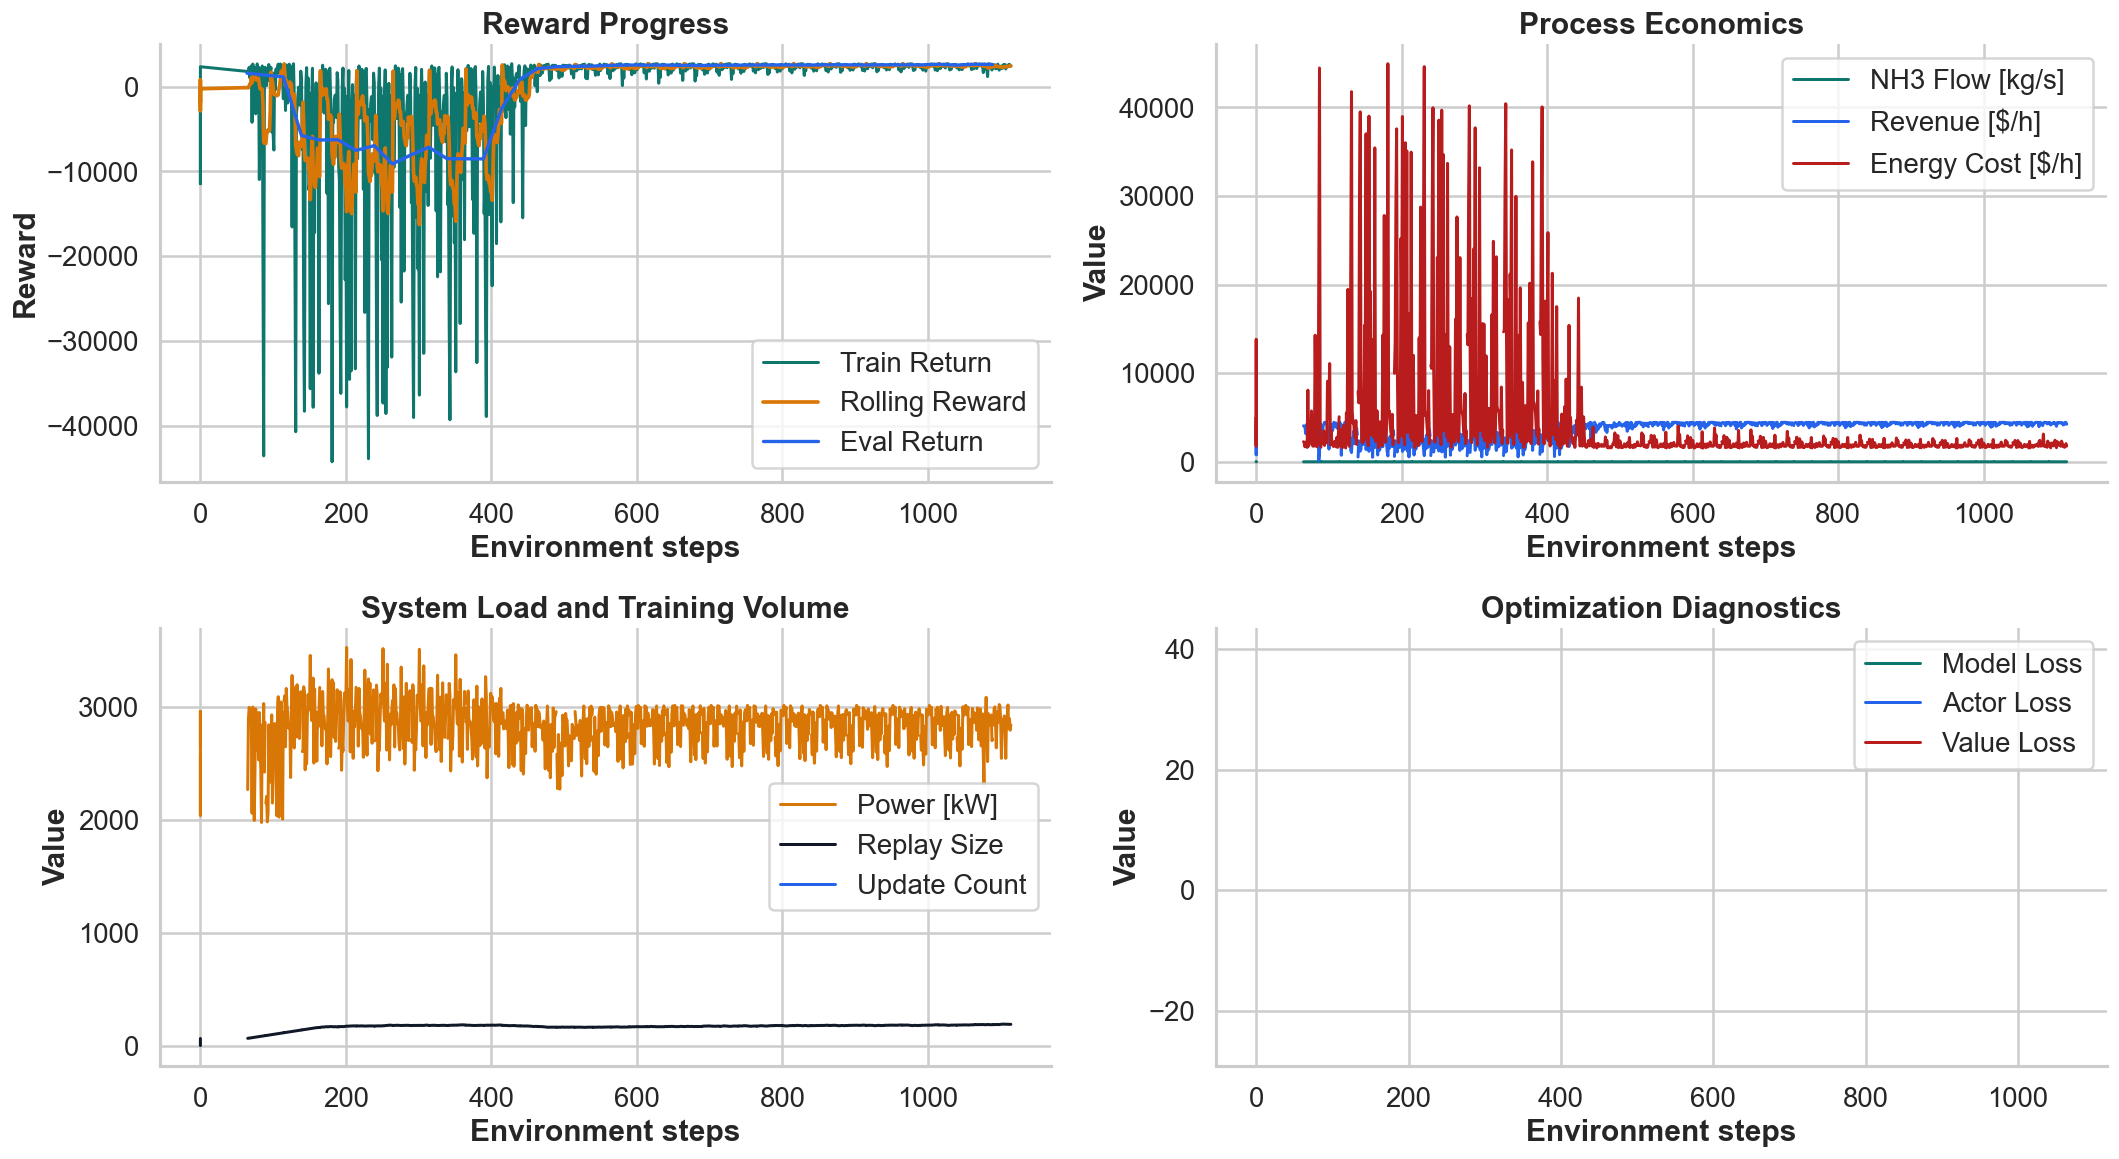

In [8]:
metrics_path = RUN_LOGDIR / 'metrics.jsonl'
if not metrics_path.exists():
    print('Run the adaptive training loop first to generate metrics for analysis.')
else:
    analysis_metrics, analysis_train, analysis_eval = load_train_metrics(RUN_LOGDIR)
    analysis_train_summary, analysis_train = summarize_train_progress(analysis_train, SUCCESS_MIN_REWARD, CONVERGENCE_WINDOW)
    analysis_eval_summary, analysis_eval = summarize_eval_progress(analysis_eval, SUCCESS_MIN_REWARD, STRETCH_REWARD, EVAL_STABILITY_WINDOW)

    phase_lookup = {str(spec['name']): spec for spec in PHASE_SPECS}
    analysis_phase_name = phase_history[-1]['phase'] if phase_history else str(PHASE_SPECS[-1]['name'])
    analysis_cfg = build_phase_config(BASE_CFG, phase_lookup[analysis_phase_name], reset_existing_run=False)
    replay_inventory, replay_selected = summarize_replay_selection(RUN_LOGDIR, analysis_cfg, SUCCESS_MIN_REWARD)

    summary_frame = pd.DataFrame([
        {
            'logdir': str(RUN_LOGDIR),
            'analysis_phase': analysis_phase_name,
            'success_min_reward': SUCCESS_MIN_REWARD,
            'stretch_reward': STRETCH_REWARD,
            'best_train_reward': float(analysis_train_summary['best_train_reward']),
            'best_train_fraction': float(analysis_train_summary['best_train_fraction']),
            'rolling_mean': float(analysis_train_summary['rolling_mean']),
            'rolling_mean_fraction': float(analysis_train_summary['rolling_mean_fraction']),
            'best_eval_return': float(analysis_eval_summary['best_eval_return']),
            'best_eval_fraction': float(analysis_eval_summary['best_eval_fraction']),
            'latest_eval_return': float(analysis_eval_summary['latest_eval_return']),
            'latest_eval_fraction': float(analysis_eval_summary['latest_eval_fraction']),
            'mean_last_eval': float(analysis_eval_summary['mean_last_eval']),
            'mean_last_eval_fraction': float(analysis_eval_summary['mean_last_eval_fraction']),
            'tail_std': float(analysis_eval_summary['tail_std']),
            'stable_success_band': bool(analysis_eval_summary['stable_success_band']),
            'stable_stretch_band': bool(analysis_eval_summary['stable_stretch_band']),
            'selected_replay_rows': int(len(replay_selected)),
            'selected_replay_success_hits': int(replay_selected['meets_target'].fillna(False).sum()) if not replay_selected.empty else 0,
        }
    ])
    display(summary_frame)

    if phase_history:
        display(pd.DataFrame(phase_history))

    if not analysis_eval.empty:
        display(analysis_eval.tail(EVAL_STABILITY_WINDOW)[['step', 'eval_return', 'tail_mean', 'tail_std', 'success_hit', 'stretch_hit']])
    if not analysis_train.empty:
        display(analysis_train.tail(CONVERGENCE_WINDOW)[['step', 'train_return', 'rolling_mean', 'rolling_hit_rate', 'success_hit']])
    if not replay_selected.empty:
        display(replay_selected.head(20))

    hb.plot_training_diagnostics(analysis_metrics)

In [9]:
comparison_runs = {
    'adaptive_96to100': RUN_LOGDIR,
    'close_gap_98_attempt': WORKSPACE_DIR / 'runs' / 'dreamerv3_haber_bosch_target95_elite_replay_close_gap',
    'target95_elite_replay': WORKSPACE_DIR / 'runs' / 'dreamerv3_haber_bosch_target95_elite_replay',
    'bo_seeded': WORKSPACE_DIR / 'runs' / 'dreamerv3_haber_bosch_bo_seeded',
    'vanilla': WORKSPACE_DIR / 'runs' / 'dreamerv3_haber_bosch',
}

comparison_rows = []
for label, logdir in comparison_runs.items():
    row = compare_run_to_band(logdir, SUCCESS_MIN_REWARD, STRETCH_REWARD)
    row['label'] = label
    comparison_rows.append(row)

comparison_frame = pd.DataFrame(comparison_rows)
comparison_frame = comparison_frame.loc[comparison_frame['status'] == 'ok'].copy()
if not comparison_frame.empty:
    comparison_frame = comparison_frame.sort_values(
        ['mean_last_eval_fraction', 'best_eval_fraction'],
        ascending=[False, False],
    ).reset_index(drop=True)
display(comparison_frame)

,logdir,status,episodes,best_train_reward,best_train_fraction,rolling_mean,rolling_mean_fraction,best_eval_return,best_eval_fraction,latest_eval_return,latest_eval_fraction,mean_last_eval,mean_last_eval_fraction,tail_std,stable_success_band,stable_stretch_band,label
0,/Users/campatzis/Documents/Research/runs/dream...,ok,1114,2712.657715,1.000002,2395.737356,0.883172,2649.391357,0.976679,2619.611084,0.965701,2605.574951,0.960527,52.267613,True,False,adaptive_96to100
1,/Users/campatzis/Documents/Research/runs/dream...,ok,1464,2712.623779,0.999990,2261.295271,0.833611,2600.450732,0.958638,2595.043750,0.956645,2596.140023,0.957049,3.880505,False,False,close_gap_98_attempt
2,/Users/campatzis/Documents/Research/runs/dream...,ok,1664,2711.016846,0.999397,2351.456950,0.866848,2582.192773,0.951907,2572.953125,0.948501,2554.366976,0.941649,17.087174,False,False,target95_elite_replay
3,/Users/campatzis/Documents/Research/runs/dream...,ok,2776,2711.665771,0.999637,2493.899492,0.919359,2509.461133,0.925095,2509.347314,0.925053,2509.378792,0.925065,0.071965,False,False,bo_seeded
4,/Users/campatzis/Documents/Research/runs/dream...,ok,2264,2711.665771,0.999637,2483.445229,0.915505,2508.802588,0.924852,2508.802588,0.924852,2508.765104,0.924839,0.056118,False,False,vanilla


## Readout

Judge the run with four questions:

1. Did the last few eval checkpoints average at or above 96% of the BO optimum?
2. Is the stable eval average merely inside the band, or is it also pushing into the 98-100% stretch region?
3. Did the adaptive discovery-to-exploit handoff happen early enough to preserve the strong elites once they were discovered?
4. Does this schedule materially outperform the earlier target95 and close-gap Dreamer runs on best eval and last-eval mean?